# 01 · Crop recommendation (XGBoost)

**Question the model answers:** given soil nutrients and local climate, which crops fit best?

| | |
|---|---|
| Dataset | [Crop Recommendation Dataset — Kaggle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset) |
| File | `ml/data/raw/crop_recommendation/Crop_recommendation.csv` |
| Rows / classes | 2,200 / 22 crops (balanced, 100 each) |
| Features | `N, P, K` (soil nutrients), `temperature` °C, `humidity` %, `ph`, `rainfall` mm |
| Model | XGBoost multi-class (`multi:softprob`) → top-k crops with probabilities |

**Division of labour (spec §6, §40).** The model predicts from numbers it was trained on.
Season, irrigation, soil type and crop rotation are *not* in this dataset, so the backend
applies them as transparent agronomic rules (`backend/app/crop/rules.py`) on top of the
model's probabilities. Crop facts (duration, water need, yield range) come from the crop
catalog, never from the model.

In [1]:
import sys
from pathlib import Path

ML_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agrismart_ml.registry import ARTIFACTS_DIR, DATA_DIR

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 4)
print("Data folder:     ", DATA_DIR)
print("Artifacts folder:", ARTIFACTS_DIR)

Data folder:      C:\AgriSmart\ml\data\raw
Artifacts folder: C:\AgriSmart\ml\artifacts


In [2]:
from agrismart_ml import crop

DATA = DATA_DIR / "crop_recommendation" / "Crop_recommendation.csv"
assert DATA.exists(), f"Download the dataset and place the CSV at {DATA}"
frame = crop.load(DATA)
frame.head()

Loaded 2200 rows (0 dropped), 22 crops


,nitrogen,phosphorus,potassium,temperature,humidity,ph,rainfall,label,crop
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,rice


## Explore
A balanced dataset: every crop has the same number of rows. Check value ranges — the backend warns farmers when their soil values fall outside them.

In [3]:
frame[crop.NUMERIC].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
nitrogen,2200.0,50.6,36.9,0.0,21.0,37.0,84.2,140.0
phosphorus,2200.0,53.4,33.0,5.0,28.0,51.0,68.0,145.0
potassium,2200.0,48.1,50.6,5.0,20.0,32.0,49.0,205.0
temperature,2200.0,25.6,5.1,8.8,22.8,25.6,28.6,43.7
humidity,2200.0,71.5,22.3,14.3,60.3,80.5,89.9,100.0
ph,2200.0,6.5,0.8,3.5,6.0,6.4,6.9,9.9
rainfall,2200.0,103.5,55.0,20.2,64.6,94.9,124.3,298.6


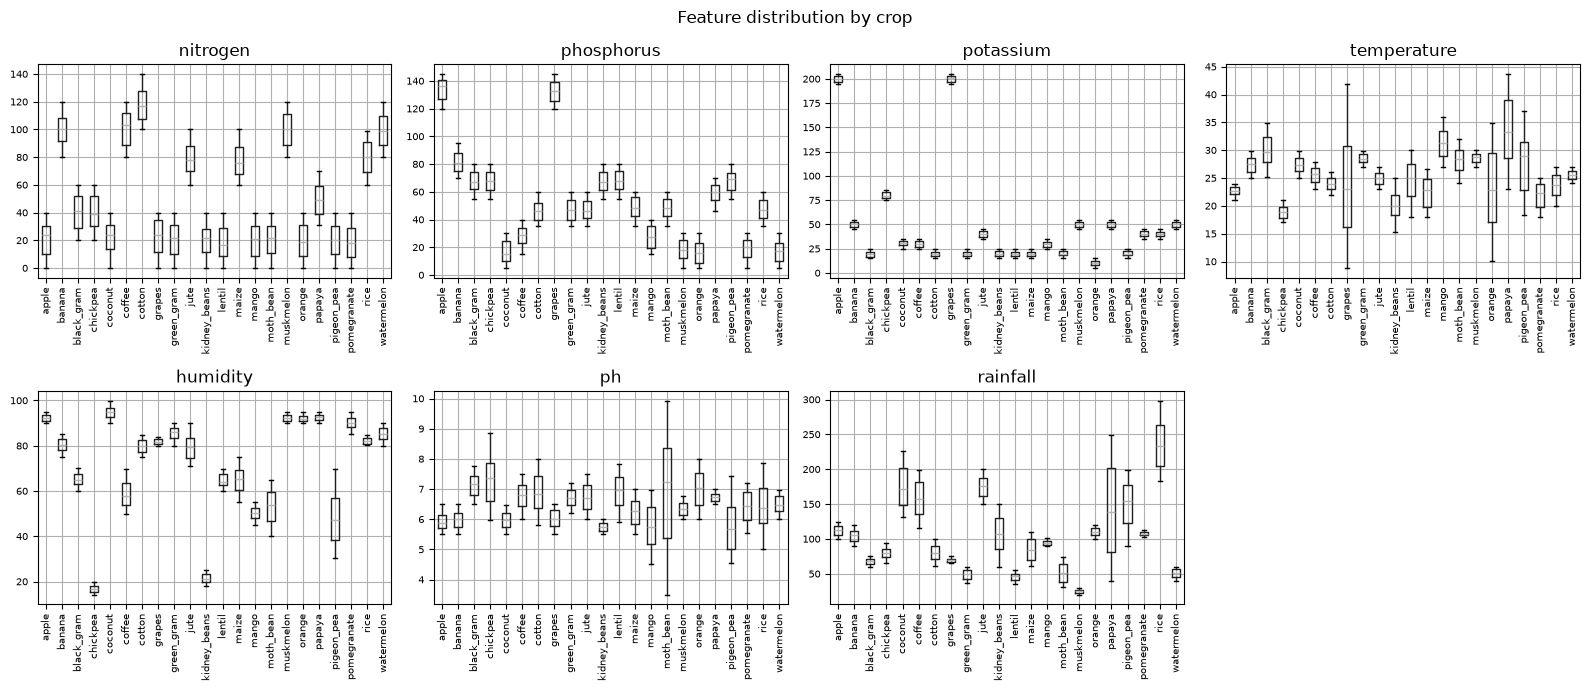

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, crop.NUMERIC):
    frame.boxplot(column=column, by="crop", ax=ax, rot=90, fontsize=7)
    ax.set_title(column); ax.set_xlabel("")
axes.flat[-1].axis("off")
plt.suptitle("Feature distribution by crop"); plt.tight_layout()

## Train
Stratified 80/20 hold-out, plus 5-fold cross-validation on the training part to check the score is stable.

## Tune hyperparameters
Random search over tree depth, learning rate, sampling and regularisation. Each candidate is
scored by **5-fold cross-validated log loss on the training split only** — the 20 % hold-out is
never used for choosing, so its score below remains an honest estimate. Log loss (not just
accuracy) is the target because the app shows *probabilities* for the top crops.

In [5]:
TRIALS = 40  # ~2 s each on a laptop CPU; raise for a wider search
search = crop.tune(frame, trials=TRIALS)
best = search.iloc[0]
print(f"best CV log loss {best.cv_log_loss:.4f}, CV accuracy {best.cv_accuracy:.4f}")
print("best params:", best.params)
search[["cv_log_loss", "cv_accuracy"]].head(10).round(4)

best CV log loss 0.0305, CV accuracy 0.9926
best params: {'n_estimators': 800, 'max_depth': 8, 'learning_rate': 0.05, 'subsample': 1.0, 'colsample_bytree': 0.6, 'min_child_weight': 1, 'reg_lambda': 2.0}


,cv_log_loss,cv_accuracy
0,0.0305,0.9926
1,0.0311,0.9955
2,0.0327,0.9932
3,0.0337,0.9920
4,0.0338,0.9926
5,0.0345,0.9920
6,0.0371,0.9903
7,0.0372,0.9903
8,0.0405,0.9898
9,0.0412,0.9915


In [6]:
baseline = crop.train(frame)                    # library defaults, for comparison only
trained = crop.train(frame, params=best.params)  # the model we export
pd.DataFrame({"default params": baseline.metrics, "tuned params": trained.metrics})

,default params,tuned params
test_accuracy,0.9955,0.9955
test_macro_f1,0.9955,0.9955
test_top3_accuracy,1.0000,1.0000
test_log_loss,0.0198,0.0197
cv_accuracy_mean,0.9915,0.9926
cv_accuracy_std,0.0040,0.0043
train_rows,1760.0000,1760.0000
test_rows,440.0000,440.0000


In [7]:
print(crop.report(trained))

              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
  black_gram      1.000     1.000     1.000        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
  green_gram      1.000     1.000     1.000        20
        jute      0.952     1.000     0.976        20
kidney_beans      1.000     1.000     1.000        20
      lentil      1.000     1.000     1.000        20
       maize      1.000     1.000     1.000        20
       mango      1.000     1.000     1.000        20
   moth_bean      0.952     1.000     0.976        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000     1.000        20
      papaya      1.000    

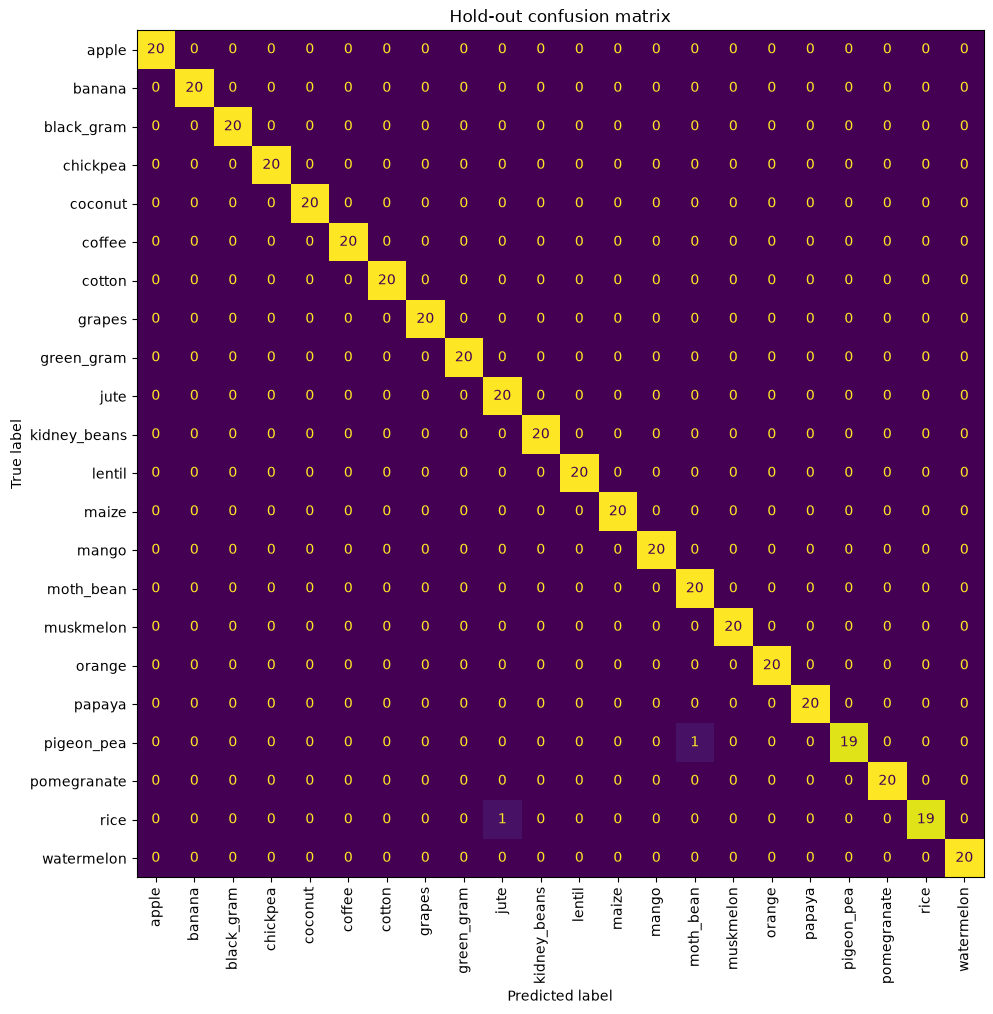

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

y_true = trained.test_frame["crop"].map({l: i for i, l in enumerate(trained.labels)})
fig, ax = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay.from_predictions(y_true, trained.test_predictions, display_labels=trained.labels,
                                        xticks_rotation=90, ax=ax, colorbar=False)
ax.set_title("Hold-out confusion matrix");

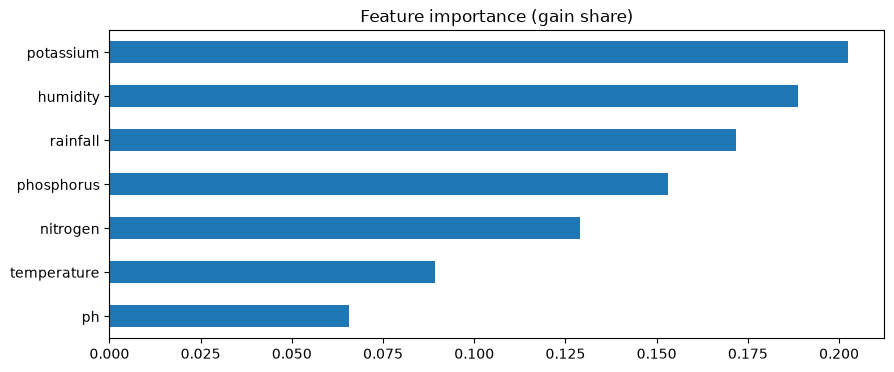

In [9]:
importance = pd.Series(trained.model.feature_importances_, index=crop.NUMERIC).sort_values()
importance.plot.barh(title="Feature importance (gain share)");

## Sanity check
Typical agronomic profiles should land on the expected crops.

In [10]:
profiles = pd.DataFrame([
    {"nitrogen": 80, "phosphorus": 45, "potassium": 40, "temperature": 24, "humidity": 82, "ph": 6.4, "rainfall": 230},  # paddy country
    {"nitrogen": 40, "phosphorus": 68, "potassium": 80, "temperature": 18, "humidity": 17, "ph": 7.3, "rainfall": 80},   # dry rabi
    {"nitrogen": 118, "phosphorus": 46, "potassium": 20, "temperature": 24, "humidity": 80, "ph": 6.9, "rainfall": 80},  # cotton belt
])
probabilities = trained.model.predict_proba(profiles[crop.NUMERIC].to_numpy())
for row in probabilities:
    top = np.argsort(row)[::-1][:3]
    print([(trained.labels[i], round(float(row[i]), 3)) for i in top])

[('rice', 0.992), ('jute', 0.007), ('coconut', 0.0)]
[('chickpea', 0.996), ('kidney_beans', 0.001), ('black_gram', 0.0)]
[('cotton', 0.996), ('maize', 0.001), ('banana', 0.0)]


## Regional planting prior
The Kaggle data has 22 crops and no region, season or irrigation, so on its own it cannot
suggest wheat in Punjab's rabi season. The government crop statistics in the yield dataset
record what farmers actually plant: area per crop, state, season and year. Each crop's share
of the cropped area (2010 onwards) is exported with the model. The backend ranks

**score ∝ soil/climate fit (this model) × regional share × agronomic rules**

That is the posterior: the balanced training classes make the model's probability act as a
likelihood. Crops this model does not cover get a neutral soil score and are ranked by region
and rules.

In [11]:
PRIOR_DATA = DATA_DIR / "crop_yield" / "crop_yield.csv"
assert PRIOR_DATA.exists(), f"Needed for the regional prior: {PRIOR_DATA}"
prior = crop.regional_prior(PRIOR_DATA)
print(len(prior), "states with planting data")
pd.DataFrame({f"{s} · {season}": pd.Series(prior[s][season]).head(5)
              for s, season in [("Punjab", "rabi"), ("Punjab", "kharif"), ("Tamil Nadu", "kharif"),
                                ("Maharashtra", "kharif"), ("West Bengal", "kharif")]}).fillna("").round(3)

30 states with planting data


,Punjab · rabi,Punjab · kharif,Tamil Nadu · kharif,Maharashtra · kharif,West Bengal · kharif
black_gram,,,,,0.0633
coconut,,,0.1145,,0.0318
cotton,,0.1066,,0.2845,
green_gram,0.0015,0.0014,,,
groundnut,,,0.0798,,
jute,,,,,0.5861
maize,,0.0343,0.0657,,0.0479
mustard,0.0085,,,,
pigeon_pea,,,,0.086,
rice,,0.835,0.4297,0.1004,0.2402


## Know the limits before shipping

* This public dataset is small and partly synthetic; near-perfect accuracy here does **not**
  mean near-perfect advice in a real field. Treat the score as a sanity check.
* Its N/P/K scale is lower than typical Soil Health Card values (kg/ha). The backend stores
  `feature_ranges` from this data and flags out-of-range inputs instead of guessing silently.
* For production, retrain on local data (Soil Health Card records joined with what farmers
  actually grew successfully) — same code, new CSV with the same columns, new version.

## Export

In [12]:
directory = crop.export(trained, DATA, prior=prior, prior_path=PRIOR_DATA)
print((directory / "metadata.json").read_text()[:800])

Exported C:\AgriSmart\ml\artifacts\crop\crop_v3


{
  "name": "crop",
  "version": "crop_v3",
  "trained_at": "2026-10-02T09:30:29.008883+00:00",
  "framework": "xgboost",
  "task": "classification",
  "artifact": "model.json",
  "dataset_version": "Crop_recommendation.csv@54a5a6e54086",
  "feature_version": "crop_features_v1",
  "metrics": {
    "test_accuracy": 0.9955,
    "test_macro_f1": 0.9955,
    "test_top3_accuracy": 1.0,
    "test_log_loss": 0.0197,
    "cv_accuracy_mean": 0.9926,
    "cv_accuracy_std": 0.0043,
    "train_rows": 1760,
    "test_rows": 440
  },
  "features": {
    "numeric": [
      "nitrogen",
      "phosphorus",
      "potassium",
      "temperature",
      "humidity",
      "ph",
      "rainfall"
    ],
    "categorical": {}
  },
  "labels": [
    "apple",
    "banana",
    "black_gram",
    "chickpea",
    "co


## Put the model live

Versions are never overwritten — each export creates a new `…_vN` folder. To serve it:

* **Admin dashboard → Models →** *Register* and tick *Activate*, or
* from `backend/`: `python -m app.cli register-model crop <version> --activate`

Rolling back is the same command with the previous version (`activate-model`). Every API
instance picks up the change within a minute — no restart.